# Week 1 — Python for Machine Learning & Data Preprocessing

**Yuva Internship · Week 1**

This notebook is the guided, runnable companion to the Week 1 report. It teaches the
Python, NumPy and Pandas skills the week asks for, then applies them to a real
preprocessing task on the bundled customer-churn sample.

### What you will be able to do by the end

| Part | Skill | Section |
|---|---|---|
| 1 | Python variables, containers, functions, loops | Python fundamentals |
| 2 | NumPy arrays, vectorisation, broadcasting, statistics | NumPy fundamentals |
| 3 | Load and inspect a table with Pandas | Pandas fundamentals |
| 4 | Clean a dataset: types, duplicates, invalid values | Data cleaning |
| 5 | Audit and impute missing values | Missing values |
| 6 | Explore data: distributions, group comparisons, correlation | Exploratory data analysis |
| 7 | Encode categorical variables | Encoding |
| 8 | Normalise / standardise numeric features | Feature scaling |
| 9 | Rank and select features | Feature selection |
| 10 | Produce the final model-ready dataset | Putting it together |

### About the dataset

`../data/customer_churn_raw.csv` is a **reproducible synthetic teaching dataset** of
1,800 customers. It is not real customer information. It deliberately contains missing
values and categorical fields so every preprocessing step has something to act on, and
it must not be used to draw conclusions about a real business.

> **How to run:** `Kernel → Restart & Run All`. Every random operation uses
> `RANDOM_STATE = 42`, so the outputs are reproducible.

---
## 0 · Setup

We import the libraries once at the top, which is the standard notebook convention.
Setting `RANDOM_STATE` in one place keeps every stochastic step reproducible.

In [1]:
import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline

RANDOM_STATE = 42
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})

DATA_PATH = Path("..", "data", "customer_churn_raw.csv")
OUTPUT_DIR = Path("..", "outputs")

print("Python     :", sys.version.split()[0])
print("NumPy      :", np.__version__)
print("Pandas     :", pd.__version__)
print("Matplotlib :", matplotlib.__version__)
print("Dataset exists:", DATA_PATH.exists(), "->", DATA_PATH.resolve())

Python     : 3.11.2
NumPy      : 2.4.6
Pandas     : 3.0.6
Matplotlib : 3.11.2
Dataset exists: True -> /home/user/Yuva_intern/week-1/data/customer_churn_raw.csv


---
## 1 · Python fundamentals

Machine-learning code is mostly ordinary Python: you hold values in variables, group
them in containers, and transform them with functions. This section revisits the
pieces used most often.

### 1.1 Variables and types

A **variable** is a name bound to a value. The value has a **type**, and the type
decides which operations are legal.

In [2]:
customer_name = "Aarav"      # str
tenure_months = 24           # int
monthly_charge = 79.99       # float
is_active = True             # bool
cancelled_on = None          # NoneType, meaning "no value"

for name, value in [
    ("customer_name", customer_name),
    ("tenure_months", tenure_months),
    ("monthly_charge", monthly_charge),
    ("is_active", is_active),
    ("cancelled_on", cancelled_on),
]:
    print(f"{name:<15} {str(value):<10} {type(value).__name__}")

customer_name   Aarav      str
tenure_months   24         int
monthly_charge  79.99      float
is_active       True       bool
cancelled_on    None       NoneType


### 1.2 Lists, tuples and dictionaries

* a **list** is an ordered, mutable collection — good for a column of values;
* a **tuple** is ordered and immutable — good for a fixed record such as `(row, column)`;
* a **dictionary** maps keys to values — good for named configuration, and it is what
  a single table row becomes when you use `DataFrame.to_dict("records")`.

In [3]:
numeric_features = ["tenure_months", "monthly_charges", "total_charges"]
categorical_features = ["contract", "internet_service"]

print("numeric features :", numeric_features)
print("first / last     :", numeric_features[0], "/", numeric_features[-1])
print("sliced           :", numeric_features[1:3])

numeric_features.append("support_tickets")          # mutate the list
print("after append     :", numeric_features)

shape = (1800, 13)                                   # tuple: immutable
print("\ntuple unpacking :", f"{shape[0]} rows x {shape[1]} columns")

feature_roles = {
    "tenure_months": "numeric",
    "monthly_charges": "numeric",
    "contract": "categorical",
    "churn": "target",
}
print("\ndictionary lookup:", feature_roles["contract"])
for feature, role in feature_roles.items():
    print(f"  {feature:<16} -> {role}")

numeric features : ['tenure_months', 'monthly_charges', 'total_charges']
first / last     : tenure_months / total_charges
sliced           : ['monthly_charges', 'total_charges']
after append     : ['tenure_months', 'monthly_charges', 'total_charges', 'support_tickets']

tuple unpacking : 1800 rows x 13 columns

dictionary lookup: categorical
  tenure_months    -> numeric
  monthly_charges  -> numeric
  contract         -> categorical
  churn            -> target


### 1.3 Functions

A **function** packages a repeatable calculation behind a name. Good functions do one
job, take explicit arguments, and return a value. The function below is the exact
missing-value rule we apply later in the pipeline, so you can see where the design
comes from.

Every function should document *why*, not only *what*. The docstring below is read by
`help()` and by every teammate who inherits the code.

In [4]:
def describe_missing(series, name):
    """Summarise missingness in one column.

    Parameters
    ----------
    series : pandas.Series
        The column to inspect.
    name : str
        Human-readable label used in the returned dictionary.

    Returns
    -------
    dict with the column name, the count and the percentage of missing cells.
    """
    missing_count = int(series.isna().sum())
    missing_percent = 100.0 * missing_count / len(series)
    return {
        "feature": name,
        "missing": missing_count,
        "missing_percent": round(missing_percent, 2),
    }


print(describe_missing(pd.Series([1.0, None, 3.0, None]), "demo_column"))
print(describe_missing(pd.Series(["a", "b", "a"]), "no_gaps"))

{'feature': 'demo_column', 'missing': 2, 'missing_percent': 50.0}
{'feature': 'no_gaps', 'missing': 0, 'missing_percent': 0.0}


### 1.4 Loops, conditionals and comprehensions

A **loop** repeats work; a **conditional** chooses a branch; a **comprehension** builds
a collection in one expressive line. Comprehensions are idiomatic Python and appear
constantly in data code.

In [5]:
# Loop + conditional: sort features into roles by a naming rule.
roles = {}
for feature in ["tenure_months", "contract", "churn"]:
    if feature == "churn":
        roles[feature] = "target"
    elif feature.endswith("_months"):
        roles[feature] = "numeric"
    else:
        roles[feature] = "categorical"
print("loop result        :", roles)

# Comprehension: the same idea, shorter.
roles_fast = {
    f: ("target" if f == "churn" else "numeric" if f.endswith("_months") else "categorical")
    for f in ["tenure_months", "contract", "churn"]
}
print("comprehension      :", roles_fast)

# Comprehension with a filter: keep only numeric column names.
columns = ["tenure_months", "contract", "monthly_charges", "churn"]
numeric_columns = [c for c in columns if c not in {"contract", "churn"}]
print("filtered           :", numeric_columns)

# enumerate gives you the position and the value together.
for position, column in enumerate(numeric_columns, start=1):
    print(f"  {position}. {column}")

loop result        : {'tenure_months': 'numeric', 'contract': 'categorical', 'churn': 'target'}
comprehension      : {'tenure_months': 'numeric', 'contract': 'categorical', 'churn': 'target'}
filtered           : ['tenure_months', 'monthly_charges']
  1. tenure_months
  2. monthly_charges


### 1.5 Errors tell you what to fix

Reading a traceback from the **bottom up** is a core skill. Python names the exception
type and the exact line. Wrapping risky code in `try`/`except` turns a crash into a
controlled message — useful when a pipeline reads many files.

In [6]:
try:
    result = "1,800" + 13          # cannot add text and an integer
except TypeError as error:
    print(f"Caught {type(error).__name__}: {error}")

try:
    value = {"rows": 1800}["columns"]
except KeyError as error:
    print(f"Caught {type(error).__name__}: missing key {error}")

print("\nThe script kept running because the errors were handled.")

Caught TypeError: can only concatenate str (not "int") to str
Caught KeyError: missing key 'columns'

The script kept running because the errors were handled.


---
## 2 · NumPy fundamentals

NumPy provides the **ndarray**: a fixed-type, contiguous block of numbers. Because all
elements share one type, NumPy can loop in compiled C instead of Python — this is
called **vectorisation** and it is often 10–100× faster than a Python loop.

Almost every library in the ML stack (Pandas, scikit-learn, PyTorch) passes arrays
around internally, so understanding shape, dtype and axis is essential.

### 2.1 Creating arrays and reading `shape` / `dtype`

In [7]:
from_list = np.array([1, 2, 3, 4, 5])
print("from list    :", from_list, "| dtype:", from_list.dtype, "| shape:", from_list.shape)

zeros = np.zeros((2, 3))                 # 2 rows, 3 columns
ones = np.ones((3,))                     # a flat vector of length 3
sequence = np.arange(0, 10, 2)           # start, stop (exclusive), step
grid = np.linspace(0, 1, 5)              # 5 evenly spaced values including endpoints
identity = np.eye(3)                     # 3x3 identity matrix

print("\nzeros(2,3):\n", zeros)
print("\nones(3):", ones)
print("\narange(0,10,2):", sequence)
print("\nlinspace(0,1,5):", grid)
print("\neye(3):\n", identity)

# Attributes, not functions.
print("\nndim:", zeros.ndim, "| size:", zeros.size, "| itemsize:", zeros.itemsize, "bytes")

from list    : [1 2 3 4 5] | dtype: int64 | shape: (5,)

zeros(2,3):
 [[0. 0. 0.]
 [0. 0. 0.]]

ones(3): [1. 1. 1.]

arange(0,10,2): [0 2 4 6 8]

linspace(0,1,5): [0.   0.25 0.5  0.75 1.  ]

eye(3):
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]

ndim: 2 | size: 6 | itemsize: 8 bytes


### 2.2 Vectorisation versus a Python loop

Both blocks compute the same thing. The vectorised version has no Python-level loop:
the arithmetic is applied to the whole array at once.

In [8]:
import time

values = np.arange(1, 1_000_001, dtype=float)

start = time.perf_counter()
loop_result = [value * 2 + 1 for value in values]
loop_seconds = time.perf_counter() - start

start = time.perf_counter()
vector_result = values * 2 + 1
vector_seconds = time.perf_counter() - start

print(f"Python loop : {loop_seconds * 1000:7.1f} ms")
print(f"NumPy       : {vector_seconds * 1000:7.1f} ms")
print(f"Speed-up    : {loop_seconds / vector_seconds:7.1f}x")
print("Same answer :", np.allclose(np.array(loop_result), vector_result))

Python loop :   164.8 ms
NumPy       :     7.5 ms
Speed-up    :    21.8x


Same answer : True


### 2.3 Indexing, slicing and boolean masks

A **boolean mask** is an array of `True`/`False` of the same shape as the data. Using it
to index the array keeps only the `True` positions. This is how filtering works in
Pandas too.

In [9]:
matrix = np.array([[10, 20, 30],
                   [40, 50, 60],
                   [70, 80, 90]])
print("matrix:\n", matrix)
print("\nrow 0            :", matrix[0])
print("column 1         :", matrix[:, 1])
print("element (2, 2)   :", matrix[2, 2])
print("sub-block        :\n", matrix[:2, 1:])

charges = np.array([18.00, 55.50, 92.10, 105.00, 64.30])
mask = charges > 60
print("\nmask             :", mask)
print("charges > 60     :", charges[mask])
print("count above 60   :", int(mask.sum()))
print("mean of the rest :", charges[~mask].mean().round(2))

matrix:
 [[10 20 30]
 [40 50 60]
 [70 80 90]]

row 0            : [10 20 30]
column 1         : [20 50 80]
element (2, 2)   : 90
sub-block        :
 [[20 30]
 [50 60]]

mask             : [False False  True  True  True]
charges > 60     : [ 92.1 105.   64.3]
count above 60   : 3
mean of the rest : 36.75


### 2.4 Broadcasting and `axis`

**Broadcasting** lets NumPy combine arrays of different shapes by stretching the
smaller one. In `matrix - matrix.mean(axis=0)`, the per-column means (shape `(3,)`)
are stretched across all rows.

The rule to remember: `axis=0` collapses **rows**, producing one value per **column**;
`axis=1` collapses **columns**, producing one value per **row**.

In [10]:
column_means = matrix.mean(axis=0)
print("mean per column (axis=0):", column_means)

centred = matrix - column_means          # broadcast (3,) across (3,3)
print("\ncentred matrix:\n", centred)

row_means = matrix.mean(axis=1)
print("\nmean per row (axis=1):", row_means)

# Standardisation in three lines, which is what StandardScaler does internally.
standardised = (matrix - matrix.mean(axis=0)) / matrix.std(axis=0)
print("\nstandardised:\n", np.round(standardised, 3))
print("column means after:", np.round(standardised.mean(axis=0), 10))
print("column stds  after:", np.round(standardised.std(axis=0), 10))

mean per column (axis=0): [40. 50. 60.]

centred matrix:
 [[-30. -30. -30.]
 [  0.   0.   0.]
 [ 30.  30.  30.]]

mean per row (axis=1): [20. 50. 80.]

standardised:
 [[-1.225 -1.225 -1.225]
 [ 0.     0.     0.   ]
 [ 1.225  1.225  1.225]]
column means after: [0. 0. 0.]
column stds  after: [1. 1. 1.]


### 2.5 Descriptive statistics and missing values

`np.nan` marks a missing number. The `nan`-aware functions (`np.nanmean`, `np.nanstd`,
`np.nansum`) ignore missing entries; the plain versions return `nan` for the whole
result if a single value is missing. Choosing the wrong one silently destroys a column.

In [11]:
sample = np.array([12.5, np.nan, 44.0, 18.25, np.nan, 31.0])
print("array           :", sample)
print("np.mean         :", np.mean(sample), "<- poisoned by nan")
print("np.nanmean      :", np.nanmean(sample).round(3))
print("np.nanstd       :", np.nanstd(sample).round(3))
print("np.nanmedian    :", np.nanmedian(sample))
print("np.isnan count  :", int(np.isnan(sample).sum()))
print("min / max       :", np.nanmin(sample), "/", np.nanmax(sample))
print("percentiles 25/50/75:", np.nanpercentile(sample, [25, 50, 75]))

array           : [12.5    nan 44.   18.25   nan 31.  ]
np.mean         : nan <- poisoned by nan
np.nanmean      : 26.438
np.nanstd       : 12.151
np.nanmedian    : 24.625
np.isnan count  : 2
min / max       : 12.5 / 44.0
percentiles 25/50/75: [16.8125 24.625  34.25  ]


### 2.6 Reshaping and stacking

`reshape` changes the shape without changing the data. `-1` means *"work this dimension
out from the others"*. `concatenate` and `stack` glue arrays together — used to build
the final feature matrix from separately processed numeric and encoded blocks.

In [12]:
flat = np.arange(12)
print("flat          :", flat, "shape:", flat.shape)

reshaped = flat.reshape(3, 4)
print("\nreshape(3, 4):\n", reshaped)

auto = flat.reshape(4, -1)
print("\nreshape(4, -1): shape", auto.shape)

print("\ntranspose shape:", reshaped.T.shape)
print("flatten back   :", reshaped.flatten().tolist())

numeric_block = np.ones((5, 3))
encoded_block = np.zeros((5, 2))
combined = np.hstack([numeric_block, encoded_block])
print("\nhstack -> shape:", combined.shape)

flat          : [ 0  1  2  3  4  5  6  7  8  9 10 11] shape: (12,)

reshape(3, 4):
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

reshape(4, -1): shape (4, 3)

transpose shape: (4, 3)
flatten back   : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]

hstack -> shape: (5, 5)


---
## 3 · Pandas fundamentals

Pandas gives NumPy arrays **labels**: a `Series` is a labelled column, a `DataFrame` is
a labelled table. Labelled access is why Pandas beats raw arrays for tabular data —
you refer to `df["monthly_charges"]` rather than a fragile column index.

### 3.1 Loading data

`read_csv` is the entry point. Three arguments worth knowing:

* `dtype` — force a column's type instead of trusting inference;
* `na_values` — extra strings to treat as missing;
* `usecols` — load a subset when the file is wide.

In [13]:
df = pd.read_csv(DATA_PATH, na_values=["", " ", "NA", "N/A", "unknown"])
print("raw shape:", df.shape)

df.head()

raw shape: (1800, 13)


,customer_id,tenure_months,monthly_charges,total_charges,support_tickets,senior_citizen,contract,internet_service,payment_method,paperless_billing,partner,dependents,churn
0,C000001,36.00,55.51,"2,017.09",3.00,0,Month-to-month,DSL,NaN,Yes,No,No,No
1,C000002,53.00,83.21,"4,590.07",2.00,0,One year,Fiber optic,Electronic check,No,No,No,No
2,C000003,28.00,29.07,786.73,1.00,1,Month-to-month,No,Credit card,Yes,Yes,No,No
3,C000004,70.00,31.15,"2,130.91",NaN,1,Month-to-month,No,Bank transfer,Yes,No,No,No
4,C000005,47.00,76.45,"3,641.10",2.00,0,Month-to-month,Fiber optic,Credit card,No,No,No,Yes


### 3.2 Inspecting a new table

Run these five calls on any unfamiliar dataset before anything else. They answer:
*how big is it, what are the types, what is missing, what ranges are possible, and how
do the categorical levels look?*

In [14]:
print("SHAPE -------------")
print(df.shape)

print("\nDTYPES ------------")
print(df.dtypes)

SHAPE -------------
(1800, 13)

DTYPES ------------
customer_id              str
tenure_months        float64
monthly_charges      float64
total_charges        float64
support_tickets      float64
senior_citizen         int64
contract                 str
internet_service         str
payment_method           str
paperless_billing        str
partner                  str
dependents               str
churn                    str
dtype: object


In [15]:
print("INFO --------------")
df.info()

INFO --------------
<class 'pandas.DataFrame'>
RangeIndex: 1800 entries, 0 to 1799
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        1800 non-null   str    
 1   tenure_months      1723 non-null   float64
 2   monthly_charges    1722 non-null   float64
 3   total_charges      1726 non-null   float64
 4   support_tickets    1711 non-null   float64
 5   senior_citizen     1800 non-null   int64  
 6   contract           1753 non-null   str    
 7   internet_service   1758 non-null   str    
 8   payment_method     1748 non-null   str    
 9   paperless_billing  1764 non-null   str    
 10  partner            1767 non-null   str    
 11  dependents         1766 non-null   str    
 12  churn              1800 non-null   str    
dtypes: float64(4), int64(1), str(8)
memory usage: 182.9 KB


In [16]:
print("DESCRIBE (numeric) --------------")
df.describe().T

DESCRIBE (numeric) --------------


,count,mean,std,min,25%,50%,75%,max
tenure_months,"1,723.00",37.19,17.43,1.00,23.00,37.00,52.00,71.00
monthly_charges,"1,722.00",60.73,21.82,18.00,47.78,64.34,78.06,106.24
total_charges,"1,726.00","2,227.58","1,372.35",0.00,"1,082.97","2,020.29","3,205.17","6,881.94"
support_tickets,"1,711.00",1.00,1.05,0.00,0.00,1.00,2.00,6.00
senior_citizen,"1,800.00",0.18,0.38,0.00,0.00,0.00,0.00,1.00


In [17]:
print("MISSING -----------")
missing = df.isna().sum().to_frame("missing_count")
missing["missing_percent"] = (100 * missing["missing_count"] / len(df)).round(2)
missing["dtype"] = df.dtypes.astype(str)
missing.sort_values("missing_count", ascending=False)

MISSING -----------


,missing_count,missing_percent,dtype
support_tickets,89,4.94,float64
monthly_charges,78,4.33,float64
tenure_months,77,4.28,float64
total_charges,74,4.11,float64
payment_method,52,2.89,str
contract,47,2.61,str
internet_service,42,2.33,str
paperless_billing,36,2.00,str
dependents,34,1.89,str
partner,33,1.83,str


In [18]:
print("CATEGORICAL LEVELS -----------")
for column in df.select_dtypes(exclude="number").columns:
    levels = df[column].nunique(dropna=True)
    values = ", ".join(map(str, df[column].dropna().unique()[:6]))
    print(f"{column:<18} {levels:>3} levels  ->  {values}")

CATEGORICAL LEVELS -----------
customer_id        1800 levels  ->  C000001, C000002, C000003, C000004, C000005, C000006
contract             3 levels  ->  Month-to-month, One year, Two year
internet_service     3 levels  ->  DSL, Fiber optic, No
payment_method       4 levels  ->  Electronic check, Credit card, Bank transfer, Mailed check
paperless_billing    2 levels  ->  Yes, No
partner              2 levels  ->  No, Yes
dependents           2 levels  ->  No, Yes
churn                2 levels  ->  No, Yes


### 3.3 Selecting, filtering and sorting

There are two indexers and it matters which you use:

* `.loc[rows, columns]` — **label** based;
* `.iloc[rows, columns]` — **integer position** based.

Boolean conditions combine with `&` (and), `|` (or) and `~` (not). Each condition must
be wrapped in parentheses because `&` binds more tightly than `>`.

In [19]:
# Column selection
print("Series (one column):", type(df["monthly_charges"]).__name__)
print("DataFrame (two cols):", type(df[["monthly_charges", "churn"]]).__name__)

# iloc: first 3 rows, first 4 columns by position
df.iloc[:3, :4]

Series (one column): Series
DataFrame (two cols): DataFrame


,customer_id,tenure_months,monthly_charges,total_charges
0,C000001,36.00,55.51,"2,017.09"
1,C000002,53.00,83.21,"4,590.07"
2,C000003,28.00,29.07,786.73


In [20]:
# Filtering with a boolean mask
high_bill = df[df["monthly_charges"] > 90]
print(f"Customers above 90: {len(high_bill):,}")

# Two conditions must each be parenthesised
month_to_month_high = df[(df["monthly_charges"] > 90) & (df["contract"] == "Month-to-month")]
print(f"Month-to-month AND above 90: {len(month_to_month_high):,}")

# .loc with labels, .iloc with positions
print("\n.loc row 0, columns monthly_charges..total_charges")
print(df.loc[0, "monthly_charges":"total_charges"])

print("\n.iloc row 0, first 3 columns")
print(df.iloc[0, :3])

Customers above 90: 99
Month-to-month AND above 90: 60

.loc row 0, columns monthly_charges..total_charges
monthly_charges      55.51
total_charges     2,017.09
Name: 0, dtype: object

.iloc row 0, first 3 columns
customer_id        C000001
tenure_months        36.00
monthly_charges      55.51
Name: 0, dtype: object


In [21]:
# Sorting: largest bills first
df.sort_values("monthly_charges", ascending=False).head(5)[
    ["customer_id", "contract", "monthly_charges", "churn"]
]

,customer_id,contract,monthly_charges,churn
989,C000990,One year,106.24,No
414,C000415,Month-to-month,103.32,Yes
1524,C001525,One year,102.18,Yes
1058,C001059,Month-to-month,102.14,Yes
1280,C001281,Two year,100.33,No


### 3.4 `groupby`: the most useful verb in Pandas

`groupby` splits rows into groups, applies a calculation, and combines the results —
exactly **split–apply–combine**.

`observed=True` is important with pandas' newer string dtypes: it stops Pandas from
creating an empty group for every unobserved category combination.

In [22]:
# Average numeric values per contract type
df.groupby("contract", observed=True)[["monthly_charges", "tenure_months"]].mean().round(2)

,monthly_charges,tenure_months
contract,,
Month-to-month,62.29,37.51
One year,60.36,37.47
Two year,57.07,36.20


In [23]:
# Churn rate per categorical level requires turning the label into 0/1 first.
df_work = df.copy()
df_work["churn_flag"] = df_work["churn"].map({"No": 0, "Yes": 1})

churn_by_contract = (
    df_work.groupby("contract", observed=True)
    .agg(customers=("churn_flag", "size"), churn_rate=("churn_flag", "mean"))
    .sort_values("churn_rate", ascending=False)
)
churn_by_contract["churn_rate"] = churn_by_contract["churn_rate"].round(3)
churn_by_contract

,customers,churn_rate
contract,,
Month-to-month,939,0.39
One year,454,0.18
Two year,360,0.07


### 3.5 Adding and transforming columns

`assign` returns a new DataFrame with the added columns, leaving the original
untouched. `apply` runs a function element-wise — convenient, but slower than a
vectorised expression, so prefer vectorisation on large data.

In [24]:
df_work = df_work.assign(
    annual_charge=df_work["monthly_charges"] * 12,
    tenure_years=(df_work["tenure_months"] / 12).round(1),
    is_month_to_month=df_work["contract"].eq("Month-to-month"),
)

df_work[["customer_id", "monthly_charges", "annual_charge", "tenure_years", "is_month_to_month"]].head()

,customer_id,monthly_charges,annual_charge,tenure_years,is_month_to_month
0,C000001,55.51,666.12,3.00,True
1,C000002,83.21,998.52,4.40,False
2,C000003,29.07,348.84,2.30,True
3,C000004,31.15,373.80,5.80,True
4,C000005,76.45,917.40,3.90,True


### 3.6 `pivot_table`: two dimensions at once

A pivot table is a `groupby` on two keys rendered as a grid, which makes interactions
visible that a single grouping hides.

In [25]:
pd.pivot_table(
    df_work,
    index="contract",
    columns="internet_service",
    values="churn_flag",
    aggfunc="mean",
    observed=True,
).round(3)

internet_service,DSL,Fiber optic,No
contract,,,
Month-to-month,0.23,0.59,0.13
One year,0.12,0.29,0.04
Two year,0.07,0.09,0.02


---
## 4 · Data cleaning

Real tables arrive with duplicated rows, wrong types, stray whitespace and impossible
values. Cleaning establishes that every cell means what it claims to mean.

### 4.1 Duplicate records

Two kinds of duplication matter:

* **exact duplicate rows** — the same record ingested twice;
* **duplicate identifiers** — the same entity with conflicting attribute values.

They need different handling: drop exact duplicates silently, but *investigate*
duplicate IDs, because one of the two records may be more recent.

In [26]:
print(f"Exact duplicate rows : {df.duplicated().sum()}")
print(f"Duplicate customer IDs: {df['customer_id'].duplicated().sum()}")
print(f"Unique customer IDs   : {df['customer_id'].nunique():,} of {len(df):,} rows")
print(f"customer_id dtype     : {df['customer_id'].dtype}  (text, not a number)")

Exact duplicate rows : 0
Duplicate customer IDs: 0
Unique customer IDs   : 1,800 of 1,800 rows
customer_id dtype     : str  (text, not a number)


### 4.2 Types and impossible values

A column's dtype is a promise. If `senior_citizen` is stored as text, arithmetic
silently fails. If a charge is negative, the value is impossible and should become
missing rather than be quietly averaged into the data.

In [27]:
numeric_check = ["tenure_months", "monthly_charges", "total_charges", "support_tickets", "senior_citizen"]

for column in numeric_check:
    negatives = int((df[column] < 0).sum())
    print(f"{column:<18} dtype={str(df[column].dtype):<8} min={df[column].min():>8.2f} "
          f"max={df[column].max():>9.2f} negative={negatives}")

invalid_senior = df.loc[df["senior_citizen"].notna() & ~df["senior_citizen"].isin([0, 1]), "senior_citizen"]
print("\nInvalid senior_citizen codes (must be 0 or 1):", len(invalid_senior))

tenure_months      dtype=float64  min=    1.00 max=    71.00 negative=0


monthly_charges    dtype=float64  min=   18.00 max=   106.24 negative=0
total_charges      dtype=float64  min=    0.00 max=  6881.94 negative=0
support_tickets    dtype=float64  min=    0.00 max=     6.00 negative=0
senior_citizen     dtype=int64    min=    0.00 max=     1.00 negative=0

Invalid senior_citizen codes (must be 0 or 1): 0


### 4.3 Target integrity

The **target is special**: you cannot impute a label. Every training row must have a
valid label, so invalid or missing targets must be removed, and the class balance
should be checked at the same time.

In [28]:
valid_labels = {"No", "Yes"}
invalid_target = ~df["churn"].isin(valid_labels)

print("Rows with an invalid target:", int(invalid_target.sum()))

balance = df["churn"].value_counts()
balance_df = balance.to_frame("customers")
balance_df["percent"] = (100 * balance_df["customers"] / len(df)).round(1)
print("\nClass balance:")
display(balance_df)

Rows with an invalid target: 0

Class balance:


,customers,percent
churn,,
No,1320,73.30
Yes,480,26.70


### 4.4 Text hygiene

`" Month-to-month"` and `"Month-to-month"` become two different categories after
one-hot encoding. Trimming whitespace, standardising case and mapping spelling variants
prevents phantom categories.

In [29]:
text_columns = df.select_dtypes(exclude="number").columns.drop("customer_id", errors="ignore")

whitespace_issues = {
    column: int((df[column].dropna().astype(str) != df[column].dropna().astype(str).str.strip()).sum())
    for column in text_columns
}
print("Cells needing a trim:", sum(whitespace_issues.values()), whitespace_issues)

# Spelling variants are caught by comparing the unique values count.
print("\nUnique contracts:", sorted(df["contract"].dropna().unique().tolist()))

Cells needing a trim:

 0 {'contract': 0, 'internet_service': 0, 'payment_method': 0, 'paperless_billing': 0, 'partner': 0, 'dependents': 0, 'churn': 0}



Unique contracts: ['Month-to-month', 'One year', 'Two year']


### 4.5 The cleaning function

Everything above is now written as one reusable function. It returns the cleaned frame
**and** a log describing what changed — a log is what makes a preprocessing step
auditable months later.

In [30]:
def clean_dataset(frame):
    """Apply the cleaning rules and return (clean_frame, log).

    Rules
    -----
    1. Trim text and convert empty strings to missing.
    2. Negative numerics and invalid senior_citizen codes become missing.
    3. Rows with a missing/invalid target are dropped (labels cannot be imputed).
    4. Exact duplicate rows are dropped.
    5. Duplicate customer IDs keep the first occurrence.
    """
    clean = frame.copy()
    rows_start = len(clean)
    log = {"rows_start": rows_start}

    # 1. Text hygiene
    log["whitespace_trimmed"] = 0
    for column in clean.select_dtypes(exclude="number").columns:
        series = clean[column]
        stripped = series.map(lambda v: v.strip() if isinstance(v, str) else v).replace("", np.nan)
        log["whitespace_trimmed"] += int((series.dropna().astype(str)
                                          != series.dropna().astype(str).str.strip()).sum())
        clean[column] = stripped

    # 2. Impossible values
    clean.loc[clean["senior_citizen"].notna()
              & ~clean["senior_citizen"].isin([0, 1]), "senior_citizen"] = np.nan
    log["invalid_values_to_missing"] = 0
    for column in ["tenure_months", "monthly_charges", "total_charges", "support_tickets"]:
        mask = clean[column] < 0
        log["invalid_values_to_missing"] += int(mask.sum())
        clean.loc[mask, column] = np.nan

    # 3. Target integrity
    invalid_target = ~clean["churn"].isin({"No", "Yes"})
    log["invalid_target_rows"] = int(invalid_target.sum())
    clean = clean.loc[~invalid_target]

    # 4. Exact duplicates
    log["duplicate_rows"] = int(clean.duplicated().sum())
    clean = clean.drop_duplicates()

    # 5. Duplicate identifiers
    log["duplicate_ids"] = int(clean["customer_id"].duplicated().sum())
    clean = clean.drop_duplicates(subset="customer_id", keep="first")

    log["rows_end"] = len(clean)
    return clean.reset_index(drop=True), log


clean_df, cleaning_log = clean_dataset(df)
print("Cleaning log:")
for key, value in cleaning_log.items():
    print(f"  {key:<28} {value}")

Cleaning log:
  rows_start                   1800
  whitespace_trimmed           0
  invalid_values_to_missing    0
  invalid_target_rows          0
  duplicate_rows               0
  duplicate_ids                0
  rows_end                     1800


---
## 5 · Handling missing values

### 5.1 Why values are missing

The **mechanism** decides which method is defensible.

| Mechanism | Meaning | Reasonable default |
|---|---|---|
| MCAR | Missing completely at random | Deletion is unbiased but wasteful |
| MAR | Missing depends on *observed* variables | Model-based or conditional imputation |
| MNAR | Missing depends on the *unobserved* value itself | Add a missing indicator; investigate |

You cannot prove the mechanism from the data alone, so the honest approach is:
choose a defensible default, add an indicator, and document the assumption.

### 5.2 Audit before imputing

Imputation changes the data. Audit it first so the report can state exactly how many
cells were affected and in which columns.

In [31]:
feature_columns = [c for c in clean_df.columns if c not in {"customer_id", "churn"}]
numeric_features = ["tenure_months", "monthly_charges", "total_charges", "support_tickets", "senior_citizen"]
categorical_features = [c for c in feature_columns if c not in numeric_features]

missing_audit = clean_df[feature_columns].isna().sum().to_frame("missing_count")
missing_audit["missing_percent"] = (100 * missing_audit["missing_count"] / len(clean_df)).round(2)
missing_audit["kind"] = ["numeric" if c in numeric_features else "categorical"
                         for c in missing_audit.index]
missing_audit.sort_values("missing_count", ascending=False)

,missing_count,missing_percent,kind
support_tickets,89,4.94,numeric
monthly_charges,78,4.33,numeric
tenure_months,77,4.28,numeric
total_charges,74,4.11,numeric
payment_method,52,2.89,categorical
contract,47,2.61,categorical
internet_service,42,2.33,categorical
paperless_billing,36,2.00,categorical
dependents,34,1.89,categorical
partner,33,1.83,categorical


In [32]:
print(f"Total missing feature cells: {int(clean_df[feature_columns].isna().sum().sum()):,}")
print(f"Columns affected           : {int((clean_df[feature_columns].isna().sum() > 0).sum())} of {len(feature_columns)}")
print(f"Share of the feature grid   : "
      f"{100 * clean_df[feature_columns].isna().sum().sum() / (clean_df.shape[0] * len(feature_columns)):.2f}%")

Total missing feature cells: 562
Columns affected           : 10 of 11
Share of the feature grid   : 2.84%


### 5.3 Strategy: median for numbers, mode for categories

* the **median** is robust to skew and outliers — the mean is not;
* the **mode** is the only sensible summary for an unordered category;
* a **missing indicator** preserves the fact that a value was absent, in case
  missingness is itself informative.

Both are computed on the training data only when the pipeline is used for modelling.
Here we compute them on the full cleaned sample because this section is explanatory.

In [33]:
# Learn the fill values (in a real model these are learned on the training split).
num_fill = clean_df[numeric_features].median(numeric_only=True)
cat_fill = clean_df[categorical_features].mode().iloc[0]

fill_table = pd.DataFrame({
    "kind": ["numeric"] * len(numeric_features) + ["categorical"] * len(categorical_features),
    "strategy": ["median"] * len(numeric_features) + ["mode"] * len(categorical_features),
    "fill_value": list(num_fill.round(2).values) + list(cat_fill.values),
}, index=list(num_fill.index) + list(cat_fill.index))
fill_table

,kind,strategy,fill_value
tenure_months,numeric,median,37.00
monthly_charges,numeric,median,64.34
total_charges,numeric,median,"2,020.29"
support_tickets,numeric,median,1.00
senior_citizen,numeric,median,0.00
contract,categorical,mode,Month-to-month
internet_service,categorical,mode,Fiber optic
payment_method,categorical,mode,Bank transfer
paperless_billing,categorical,mode,Yes
partner,categorical,mode,Yes


In [34]:
imputed_df = clean_df.copy()

# Numeric: median, plus a 0/1 indicator recording where we filled.
for column in numeric_features:
    was_missing = imputed_df[column].isna()
    imputed_df[f"{column}_was_missing"] = was_missing.astype(int)
    imputed_df[column] = imputed_df[column].fillna(num_fill[column])

# Categorical: most frequent value.
for column in categorical_features:
    imputed_df[column] = imputed_df[column].fillna(cat_fill[column])

remaining = int(imputed_df[feature_columns].isna().sum().sum())
print(f"Missing cells after imputation: {remaining}")
print(f"New indicator columns         : {len(numeric_features)}")

Missing cells after imputation: 0
New indicator columns         : 5


### 5.4 Imputation changes the distribution — verify it

Filling 4% of a column with one repeated value creates a **spike** at that value and
shrinks the variance. Always compare before and after.

In [35]:
comparison = pd.DataFrame({
    "mean_before": clean_df[numeric_features].mean(),
    "mean_after": imputed_df[numeric_features].mean(),
    "std_before": clean_df[numeric_features].std(),
    "std_after": imputed_df[numeric_features].std(),
}).round(3)
comparison

,mean_before,mean_after,std_before,std_after
tenure_months,37.19,37.19,17.43,17.06
monthly_charges,60.73,60.88,21.82,21.35
total_charges,"2,227.58","2,219.06","1,372.35","1,344.46"
support_tickets,1.00,1.00,1.05,1.02
senior_citizen,0.18,0.18,0.38,0.38


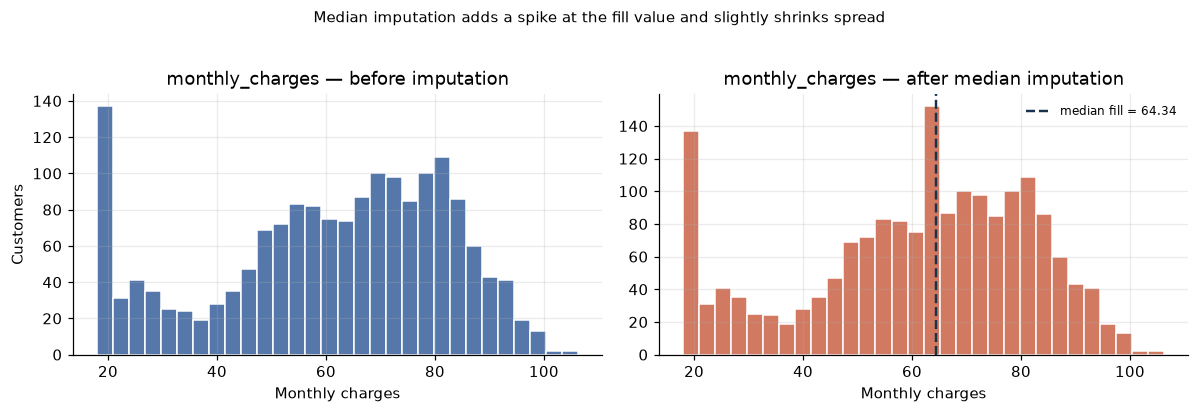

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

axes[0].hist(clean_df["monthly_charges"].dropna(), bins=30, color="#5577AA", edgecolor="white")
axes[0].set_title("monthly_charges — before imputation")
axes[0].set_xlabel("Monthly charges")
axes[0].set_ylabel("Customers")

axes[1].hist(imputed_df["monthly_charges"], bins=30, color="#D17A61", edgecolor="white")
axes[1].axvline(num_fill["monthly_charges"], color="#17324D", linestyle="--", linewidth=1.6,
                label=f"median fill = {num_fill['monthly_charges']:.2f}")
axes[1].set_title("monthly_charges — after median imputation")
axes[1].set_xlabel("Monthly charges")
axes[1].legend(frameon=False, fontsize=8)

fig.suptitle("Median imputation adds a spike at the fill value and slightly shrinks spread",
             fontsize=10, y=1.03)
plt.tight_layout()
plt.show()

### 5.5 What about deletion?

Deleting rows with any missing value is the simplest option and is sometimes right —
but only when very few cells are missing. Here it would discard roughly a quarter of
the dataset and bias the result toward customers with complete records.

In [37]:
complete_rows = len(clean_df.dropna(subset=feature_columns))
print(f"Rows kept by listwise deletion : {complete_rows:,} of {len(clean_df):,} "
      f"({100 * complete_rows / len(clean_df):.1f}%)")
print(f"Rows lost                      : {len(clean_df) - complete_rows:,} "
      f"({100 * (len(clean_df) - complete_rows) / len(clean_df):.1f}%)")
print("\nConclusion: too costly here, so impute and keep the indicator columns.")

Rows kept by listwise deletion : 1,303 of 1,800 (72.4%)
Rows lost                      : 497 (27.6%)

Conclusion: too costly here, so impute and keep the indicator columns.


---
## 6 · Exploratory data analysis

EDA answers four questions before modelling:

1. **What is the target?** How balanced is it?
2. **What do the features look like?** Shape, skew, outliers, impossible values.
3. **Which features relate to the target?** Group differences and correlation.
4. **What could go wrong?** Leakage, tiny groups, misleading scales.

### 6.1 Target balance

An imbalanced target makes plain accuracy misleading: a model that always predicts
"No" scores 73% here while learning nothing. That is why later weeks also report
precision, recall, F1 and ROC-AUC.

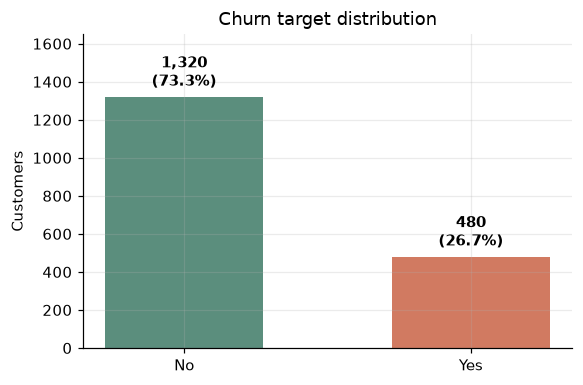

Imbalance ratio: 2.75 : 1  (No : Yes)


In [38]:
target_counts = imputed_df["churn"].value_counts().reindex(["No", "Yes"])
fig, ax = plt.subplots(figsize=(5.4, 3.6))
bars = ax.bar(target_counts.index, target_counts.values, color=["#5B8E7D", "#D17A61"], width=0.55)
ax.bar_label(bars, labels=[f"{v:,}\n({v/len(imputed_df):.1%})" for v in target_counts.values],
             padding=4, fontweight="bold")
ax.set_title("Churn target distribution")
ax.set_ylabel("Customers")
ax.set_ylim(0, target_counts.max() * 1.25)
plt.tight_layout()
plt.show()

print(f"Imbalance ratio: {target_counts['No'] / target_counts['Yes']:.2f} : 1  (No : Yes)")

### 6.2 Numeric distributions

Histograms show **shape**. Look for skew (a long tail), multiple modes (hidden
subgroups) and spikes (often a sentinel value such as 0).

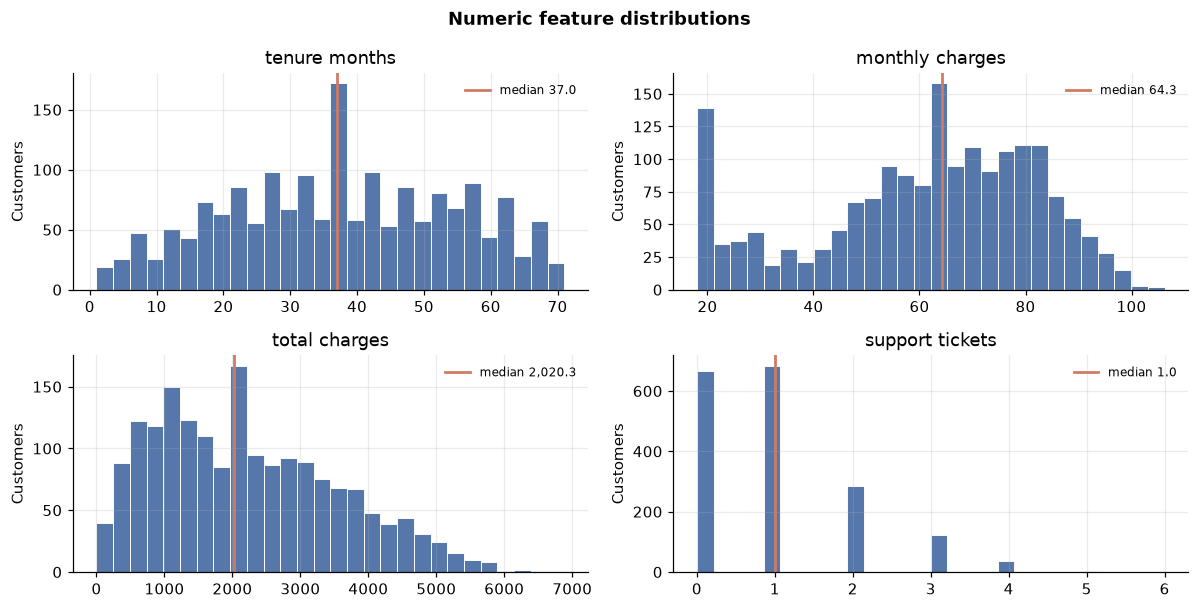

Skewness (>|1| is strongly skewed):
tenure_months     -0.04
monthly_charges   -0.53
total_charges      0.54
support_tickets    1.06


In [39]:
fig, axes = plt.subplots(2, 2, figsize=(11, 5.6))
for ax, column in zip(axes.ravel(), ["tenure_months", "monthly_charges", "total_charges", "support_tickets"]):
    values = imputed_df[column]
    ax.hist(values, bins=28, color="#5577AA", edgecolor="white", linewidth=0.6)
    ax.axvline(values.median(), color="#D17A61", linewidth=1.8, label=f"median {values.median():,.1f}")
    ax.set_title(column.replace("_", " "))
    ax.set_ylabel("Customers")
    ax.legend(frameon=False, fontsize=8)
fig.suptitle("Numeric feature distributions", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

skew = imputed_df[["tenure_months", "monthly_charges", "total_charges", "support_tickets"]].skew().round(2)
print("Skewness (>|1| is strongly skewed):")
print(skew.to_string())

### 6.3 Relationship with the target

For each categorical feature, compare the **churn rate** between levels. Differences
here are *descriptive*, not causal, and levels with few customers have wide uncertainty.

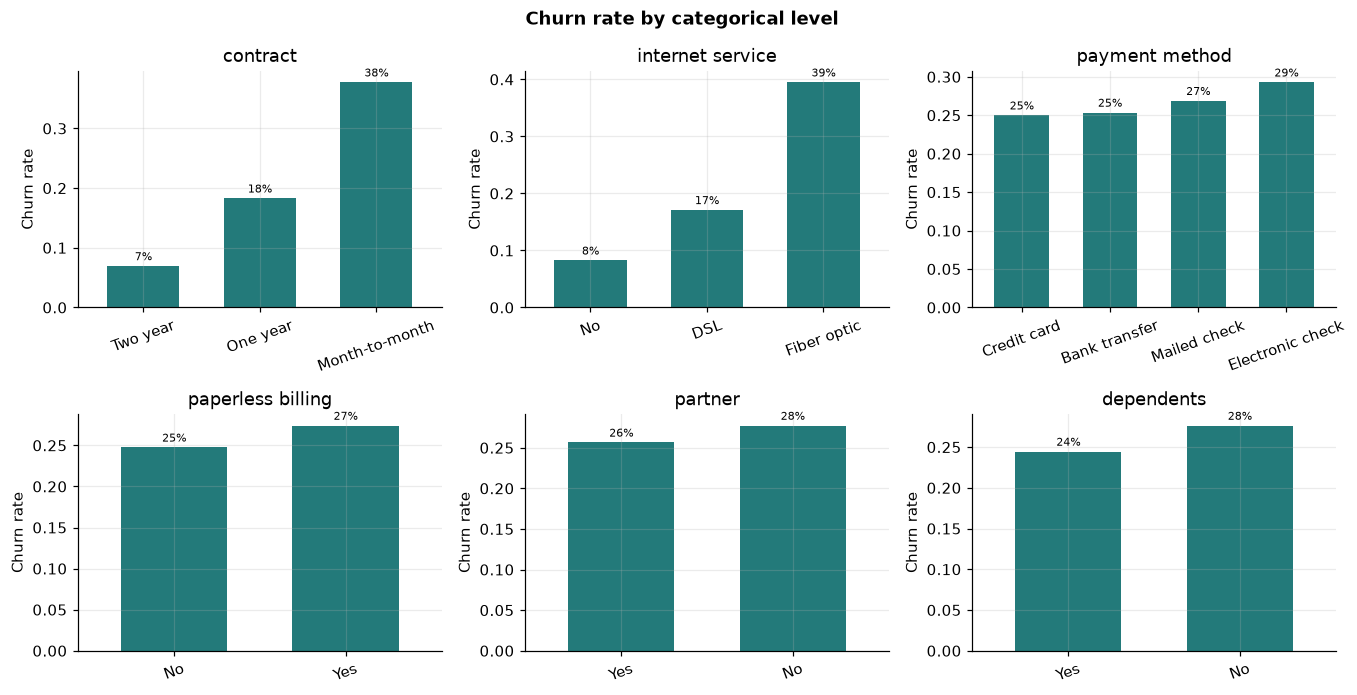

In [40]:
fig, axes = plt.subplots(2, 3, figsize=(12.5, 6.4))
for ax, column in zip(axes.ravel(), categorical_features):
    table = (imputed_df.groupby(column, observed=True)["churn"]
             .value_counts(normalize=True).unstack(fill_value=0)
             .reindex(columns=["No", "Yes"], fill_value=0))
    table["Yes"].sort_values().plot(kind="bar", ax=ax, color="#237A7A", width=0.62)
    ax.set_title(column.replace("_", " "))
    ax.set_ylabel("Churn rate")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
    for container in ax.containers:
        ax.bar_label(container, labels=[f"{v:.0%}" for v in container.datavalues], fontsize=7.5, padding=2)
fig.suptitle("Churn rate by categorical level", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

### 6.4 Correlation

Pearson correlation measures **linear** association only. A correlation near zero does
not prove independence — a strong non-linear relationship can hide there.

Watch for **collinearity** between inputs as well: `total_charges` is roughly
`monthly_charges × tenure`, which is why the two are strongly correlated and why using
both in a linear model can make coefficients unstable.

In [41]:
corr_frame = imputed_df[numeric_features].copy()
corr_frame["churn (0/1)"] = imputed_df["churn"].map({"No": 0, "Yes": 1})
correlation = corr_frame.corr().round(2)
correlation

,tenure_months,monthly_charges,total_charges,support_tickets,senior_citizen,churn (0/1)
tenure_months,1.00,-0.02,0.72,0.00,0.00,-0.14
monthly_charges,-0.02,1.00,0.55,0.14,0.05,0.32
total_charges,0.72,0.55,1.00,0.08,0.01,0.06
support_tickets,0.00,0.14,0.08,1.00,0.01,0.15
senior_citizen,0.00,0.05,0.01,0.01,1.00,0.04
churn (0/1),-0.14,0.32,0.06,0.15,0.04,1.00


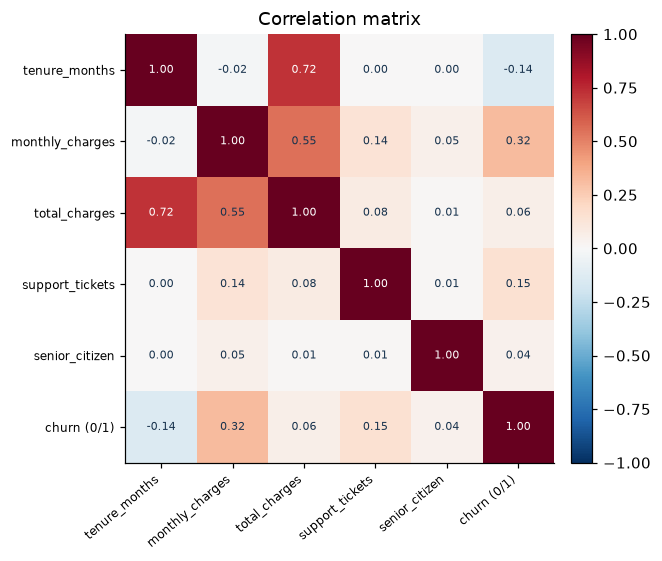

In [42]:
fig, ax = plt.subplots(figsize=(6.4, 5.2))
image = ax.imshow(correlation.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlation))); ax.set_yticks(range(len(correlation)))
ax.set_xticklabels(correlation.columns, rotation=40, ha="right", fontsize=8)
ax.set_yticklabels(correlation.columns, fontsize=8)
for row in range(len(correlation)):
    for col in range(len(correlation)):
        ax.text(col, row, f"{correlation.iloc[row, col]:.2f}", ha="center", va="center",
                fontsize=7.5, color="white" if abs(correlation.iloc[row, col]) > 0.55 else "#17324D")
ax.set_title("Correlation matrix")
ax.grid(False)
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.03)
plt.tight_layout()
plt.show()

### 6.5 Outliers: detect, then decide

The **IQR rule** flags values outside `Q1 − 1.5·IQR` and `Q3 + 1.5·IQR`. It is a
screening heuristic, not proof that a value is wrong. A single very large bill may be a
genuine valuable customer.

Binary 0/1 flags must be excluded: every `1` in a mostly-zero column would be "flagged".

In [43]:
continuous = ["tenure_months", "monthly_charges", "total_charges", "support_tickets"]
rows = []
for column in continuous:
    values = imputed_df[column]
    q1, q3 = values.quantile(0.25), values.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append({"feature": column, "q1": round(q1, 2), "q3": round(q3, 2),
                 "lower_fence": round(low, 2), "upper_fence": round(high, 2),
                 "outliers": int(((values < low) | (values > high)).sum())})
pd.DataFrame(rows)

,feature,q1,q3,lower_fence,upper_fence,outliers
0,tenure_months,24.00,51.00,-16.50,91.50,0
1,monthly_charges,48.56,77.50,5.14,120.93,0
2,total_charges,"1,116.73","3,146.15","-1,927.38","6,190.27",4
3,support_tickets,0.00,2.00,-3.00,5.00,1


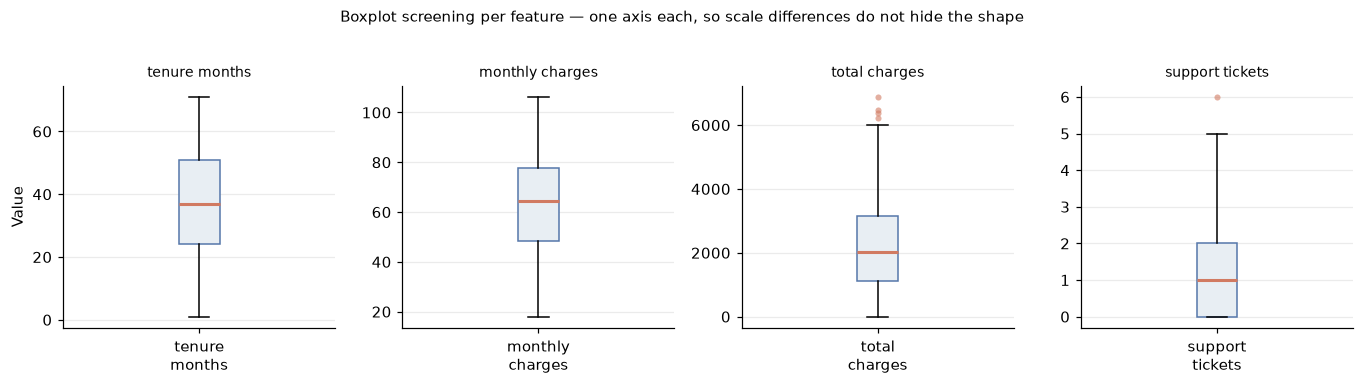

Decision: retain outliers — they are plausible bills, and tree models handle them.
A statistical model on raw units would prefer scaling (section 8) over deletion.
Note the separate axes above: plotting all four on one axis would flatten three
of them to invisible lines, because total_charges is measured in thousands.


In [44]:
fig, axes = plt.subplots(1, 4, figsize=(12.5, 3.4))
for ax, column in zip(axes, continuous):
    ax.boxplot(
        imputed_df[column],
        tick_labels=[column.replace("_", "\n")],
        patch_artist=True,
        boxprops={"facecolor": "#E8EEF3", "edgecolor": "#5577AA"},
        medianprops={"color": "#D17A61", "linewidth": 2},
        flierprops={
            "marker": "o",
            "markersize": 4,
            "markerfacecolor": "#D17A61",
            "markeredgecolor": "none",
            "alpha": 0.6,
        },
    )
    ax.set_title(column.replace("_", " "), fontsize=9)
    ax.set_ylabel("Value" if column == continuous[0] else "")
    ax.grid(axis="x", visible=False)

fig.suptitle(
    "Boxplot screening per feature — one axis each, so scale differences do not hide the shape",
    fontsize=10,
    y=1.02,
)
plt.tight_layout()
plt.show()

print("Decision: retain outliers — they are plausible bills, and tree models handle them.")
print("A statistical model on raw units would prefer scaling (section 8) over deletion.")
print("Note the separate axes above: plotting all four on one axis would flatten three")
print("of them to invisible lines, because total_charges is measured in thousands.")


---
## 7 · Encoding categorical variables

Most algorithms accept only numbers. Encoding converts text levels into numbers —
but *which* encoding matters, because some encodings invent an order that does not exist.

| Method | Output | Use when |
|---|---|---|
| **One-hot** | one 0/1 column per level | nominal data, no natural order |
| **Ordinal** | one integer column | genuinely ordered data (e.g. low < medium < high) |
| **Label** | one integer per level | tree models / when ordinals are acceptable |
| **Target / mean** | one number per level | high-cardinality data — leaks if not cross-fitted |

`contract` has no order we may assume, so **one-hot** is the safe default. `senior_citizen`
is already 0/1 and needs no encoding.

### 7.1 Manual one-hot encoding, to see the mechanics

In [45]:
demo = pd.DataFrame({"contract": ["Month-to-month", "One year", "Two year", "Month-to-month", None]})
print("before:\n", demo.to_string(index=False))

encoded = pd.get_dummies(demo["contract"], prefix="contract", dtype=int)
print("\nafter:\n", encoded.to_string())

print("\nEach row has exactly one 1 -> no invented ordering, no false magnitude.")

before:
       contract
Month-to-month
      One year
      Two year
Month-to-month
           NaN

after:
    contract_Month-to-month  contract_One year  contract_Two year
0                        1                  0                  0
1                        0                  1                  0
2                        0                  0                  1
3                        1                  0                  0
4                        0                  0                  0

Each row has exactly one 1 -> no invented ordering, no false magnitude.


### 7.2 scikit-learn `OneHotEncoder`

`get_dummies` is fine for exploration. For a pipeline, use scikit-learn's transformer
because it:

* **learns** the category list from the training data and stores it;
* supports `handle_unknown="ignore"`, which emits all zeros for an unseen level at
  prediction time instead of crashing;
* can be pickled together with the model.

In [46]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
encoded_block = encoder.fit_transform(imputed_df[categorical_features])

print("Input columns      :", len(categorical_features))
print("Output columns     :", encoded_block.shape[1])
print("Output shape       :", encoded_block.shape, "(rows, encoded columns)")
print("\nCategories learned per feature:")
for feature, levels in zip(categorical_features, encoder.categories_):
    print(f"  {feature:<20} {len(levels)} -> {list(levels)}")

Input columns      : 6
Output columns     : 16
Output shape       : (1800, 16) (rows, encoded columns)

Categories learned per feature:
  contract             3 -> ['Month-to-month', 'One year', 'Two year']
  internet_service     3 -> ['DSL', 'Fiber optic', 'No']
  payment_method       4 -> ['Bank transfer', 'Credit card', 'Electronic check', 'Mailed check']
  paperless_billing    2 -> ['No', 'Yes']
  partner              2 -> ['No', 'Yes']
  dependents           2 -> ['No', 'Yes']


In [47]:
encoded_names = encoder.get_feature_names_out(categorical_features)
pd.DataFrame(encoded_block[:5], columns=encoded_names).head()

,contract_Month-to-month,contract_One year,contract_Two year,internet_service_DSL,internet_service_Fiber optic,internet_service_No,payment_method_Bank transfer,payment_method_Credit card,payment_method_Electronic check,payment_method_Mailed check,paperless_billing_No,paperless_billing_Yes,partner_No,partner_Yes,dependents_No,dependents_Yes
0,1.00,0.00,0.00,1.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,1.00,1.00,0.00,1.00,0.00
1,0.00,1.00,0.00,0.00,1.00,0.00,0.00,0.00,1.00,0.00,1.00,0.00,1.00,0.00,1.00,0.00
2,1.00,0.00,0.00,0.00,0.00,1.00,0.00,1.00,0.00,0.00,0.00,1.00,0.00,1.00,1.00,0.00
3,1.00,0.00,0.00,0.00,0.00,1.00,1.00,0.00,0.00,0.00,0.00,1.00,1.00,0.00,1.00,0.00
4,1.00,0.00,0.00,0.00,1.00,0.00,0.00,1.00,0.00,0.00,1.00,0.00,1.00,0.00,1.00,0.00


### 7.3 Unseen categories must not crash the model

A new contract type may appear after deployment. `handle_unknown="ignore"` produces an
all-zero block instead of raising — the model then falls back on the other features.

In [48]:
unseen = pd.DataFrame({
    "contract": ["Lifetime deal"],
    "internet_service": ["Satellite"],
    "payment_method": ["Crypto"],
    "paperless_billing": ["Yes"],
    "partner": ["No"],
    "dependents": ["No"],
})

safe = encoder.transform(unseen[categorical_features])
print("Unseen input encoded without error :", safe.shape)
print("All-zero block for those levels    :", bool((safe == 0).all()))

Unseen input encoded without error : (1, 16)
All-zero block for those levels    : False


### 7.4 The dummy-variable trap

Keeping **all** one-hot columns makes them perfectly collinear: any row's values sum to
1, so one column is a linear combination of the others. For linear models fitted by
matrix inversion this is a real problem; scikit-learn's regularised solvers handle it,
but dropping one reference level (`drop="first"`) makes coefficients interpretable.

`OneHotEncoder(drop="first")` does this. It is a modelling choice, not a preprocessing
requirement, so this project keeps all levels and documents the decision.

In [49]:
print("Encoded columns in this project :", encoded_block.shape[1])
print("Sum of the 6 indicator columns for paperless_billing/partner/dependents per row:")
print("  every row sums to the number of features (3) -> a perfect linear dependency")
print("\nConsequence: one-hot columns must not be interpreted as independent effects.")

Encoded columns in this project : 16
Sum of the 6 indicator columns for paperless_billing/partner/dependents per row:
  every row sums to the number of features (3) -> a perfect linear dependency

Consequence: one-hot columns must not be interpreted as independent effects.


---
## 8 · Normalisation and standardisation

Distance- and gradient-based algorithms (KNN, K-Means, SVM, Logistic Regression with
regularisation, PCA, neural networks) compare features by magnitude. A column measured
in thousands will dominate a column measured in single digits, even if it is less
informative.

| Method | Formula | Output range | Use when |
|---|---|---|---|
| **Standardisation** (z-score) | `(x − mean) / std` | mean 0, std 1 | default; keeps outliers, assumes roughly bell-shaped |
| **Min–max normalisation** | `(x − min) / (max − min)` | exactly [0, 1] | bounded inputs required (e.g. neural nets) |
| **Robust scaling** | `(x − median) / IQR` | centred on median | many outliers |

The choice must be made from the **training data only**: computing the mean on the full
dataset leaks test information into training.

### 8.1 Standardisation by hand (NumPy)

In [50]:
raw = imputed_df["monthly_charges"].to_numpy()

manual_z = (raw - raw.mean()) / raw.std()
print(f"before: mean={raw.mean():8.3f}  std={raw.std():8.3f}  min={raw.min():7.2f}  max={raw.max():7.2f}")
print(f"after : mean={manual_z.mean():8.3f}  std={manual_z.std():8.3f}  min={manual_z.min():7.2f}  max={manual_z.max():7.2f}")
print("\nThe shape of the distribution is unchanged - only the axis is rescaled.")

before: mean=  60.884  std=  21.344  min=  18.00  max= 106.24
after : mean=  -0.000  std=   1.000  min=  -2.01  max=   2.12

The shape of the distribution is unchanged - only the axis is rescaled.


### 8.2 Min–max normalisation by hand, for comparison

Both scalers are monotonic, so neither changes the *order* of values. They differ in
what they do to the **spacing**: min–max squashes the bulk of the data into a small
range when a single large outlier is present, while standardisation does not.

In [51]:
minmax = (raw - raw.min()) / (raw.max() - raw.min())
print(f"min-max range  : [{minmax.min():.3f}, {minmax.max():.3f}]")
print(f"share of rows below 0.5 : {(minmax < 0.5).mean():.1%}")
print(f"share of z-scores below 0: {(manual_z < 0).mean():.1%}")
print("\nStandardisation is preferred here: charges are skewed with a long right tail.")

min-max range  : [0.000, 1.000]
share of rows below 0.5 : 44.6%
share of z-scores below 0: 42.8%

Standardisation is preferred here: charges are skewed with a long right tail.


### 8.3 `StandardScaler` on all numeric features

Note the parameters are **learned** by `fit` and stored, then reused by `transform`.
That is the mechanism that lets you apply the identical scaling to future data.

In [52]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
numeric_block = scaler.fit_transform(imputed_df[numeric_features])

scaling_check = pd.DataFrame({
    "mean_before": imputed_df[numeric_features].mean().round(2),
    "std_before": imputed_df[numeric_features].std().round(2),
    "mean_after": numeric_block.mean(axis=0).round(6),
    "std_after": numeric_block.std(axis=0).round(6),
}, index=numeric_features)
scaling_check

,mean_before,std_before,mean_after,std_after
tenure_months,37.18,17.06,-0.00,1.00
monthly_charges,60.88,21.35,-0.00,1.00
total_charges,"2,219.06","1,344.46",-0.00,1.00
support_tickets,1.00,1.02,0.00,1.00
senior_citizen,0.18,0.38,0.00,1.00


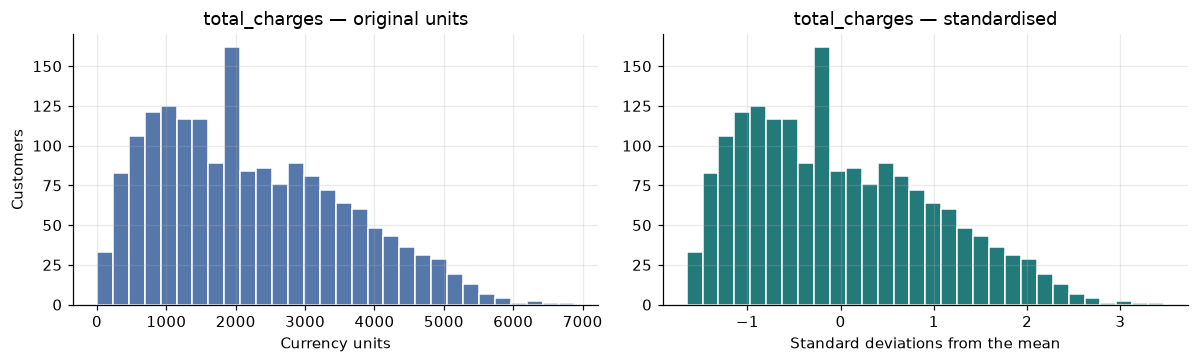

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].hist(imputed_df["total_charges"], bins=30, color="#5577AA", edgecolor="white")
axes[0].set_title("total_charges — original units")
axes[0].set_xlabel("Currency units"); axes[0].set_ylabel("Customers")

axes[1].hist(numeric_block[:, numeric_features.index("total_charges")], bins=30,
             color="#237A7A", edgecolor="white")
axes[1].set_title("total_charges — standardised")
axes[1].set_xlabel("Standard deviations from the mean")
plt.tight_layout(); plt.show()

### 8.4 The wrong way: scaling before splitting

If the scaler sees the test set while learning its mean and standard deviation, a small
amount of test information has already entered training. With a large dataset the
effect is tiny; with a small one it can inflate the reported score.

**Correct order:** split → fit the transformer on train → transform train and test.
Wrapping the scaler in a `Pipeline` makes this automatic inside cross-validation.

In [54]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

X = imputed_df[feature_columns]
y = imputed_df["churn"].map({"No": 0, "Yes": 1})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print(f"Training rows: {len(X_train):,}   Test rows: {len(X_test):,}")
print(f"Train churn rate: {y_train.mean():.3f}   Test churn rate: {y_test.mean():.3f}")
print("\nStratification kept the class balance identical in both splits.")

# Fit on train, apply to test - never the other way round.
train_scaler = StandardScaler().fit(X_train[numeric_features])
print("\nMean learned from TRAINING data only:")
print(pd.Series(train_scaler.mean_, index=numeric_features).round(3).to_string())

Training rows: 1,440   Test rows: 360
Train churn rate: 0.267   Test churn rate: 0.267

Stratification kept the class balance identical in both splits.

Mean learned from TRAINING data only:
tenure_months        37.06
monthly_charges      61.22
total_charges     2,224.84
support_tickets       1.01
senior_citizen        0.17


---
## 9 · Feature selection

More features is not better. Irrelevant and redundant features add noise, slow training,
and make a model harder to explain. Feature selection asks: *which inputs carry real
information about the target?*

| Family | How it works | Example |
|---|---|---|
| **Filter** | score each feature independently of a model | correlation, mutual information, chi-square |
| **Wrapper** | train a model repeatedly on subsets | recursive feature elimination |
| **Embedded** | selection happens during fitting | L1 / Lasso, tree importance |

### 9.1 Mutual information

**Mutual information (MI)** measures how much knowing a feature reduces uncertainty
about the target. Unlike correlation it captures **non-linear** dependence and works
with categorical targets.

* MI = 0 → independent;
* larger MI → more information;
* units are *nats* (natural-log base) and there is no universal "good" threshold.

### 9.2 Build the full encoded matrix

In [55]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
            ("scaler", StandardScaler()),
        ]), numeric_features),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), categorical_features),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

feature_matrix = preprocessor.fit_transform(X, y)
feature_names = list(preprocessor.get_feature_names_out())

print("Raw feature columns  :", len(feature_columns))
print("Encoded matrix shape :", feature_matrix.shape)
print("Missing values       :", int(np.isnan(feature_matrix).sum()))
print("\nFirst 12 encoded feature names:")
for name in feature_names[:12]:
    print("  ", name)

Raw feature columns  : 11
Encoded matrix shape : (1800, 21)
Missing values       : 0

First 12 encoded feature names:
   tenure_months
   monthly_charges
   total_charges
   support_tickets
   senior_citizen
   contract_Month-to-month
   contract_One year
   contract_Two year
   internet_service_DSL
   internet_service_Fiber optic
   internet_service_No
   payment_method_Bank transfer


### 9.3 Score every encoded feature

Discrete features (one-hot columns, 0/1 flags, missing indicators) must be declared as
discrete; treating them as continuous gives a meaningless score.

In [56]:
from sklearn.feature_selection import mutual_info_classif

discrete_mask = np.array([
    any(name.startswith(f"{column}_") for column in categorical_features)
    or name.startswith("missingindicator_")
    or name in {"senior_citizen"}
    for name in feature_names
])

# n_neighbors=5 instead of the default 3: with 1,800 rows the k-NN estimator is
# noisy, and weak signals such as tenure_months can collapse to exactly 0.
mi_scores = mutual_info_classif(
    feature_matrix,
    y.to_numpy(),
    discrete_features=discrete_mask,
    n_neighbors=5,
    random_state=RANDOM_STATE,
)

ranking = (pd.DataFrame({"feature": feature_names, "mutual_information": mi_scores.round(5)})
           .sort_values("mutual_information", ascending=False)
           .reset_index(drop=True))
ranking.index = ranking.index + 1
ranking.index.name = "rank"
ranking.head(15)

/home/user/.venv/lib/python3.11/site-packages/sklearn/metrics/cluster/_supervised.py:68: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and binary values for target
  warnings.warn(msg, UserWarning)


,feature,mutual_information
rank,,
1,monthly_charges,0.06
2,internet_service_Fiber optic,0.04
3,contract_Month-to-month,0.04
4,contract_Two year,0.03
5,internet_service_No,0.02
6,support_tickets,0.01
7,internet_service_DSL,0.01
8,total_charges,0.01
9,contract_One year,0.01


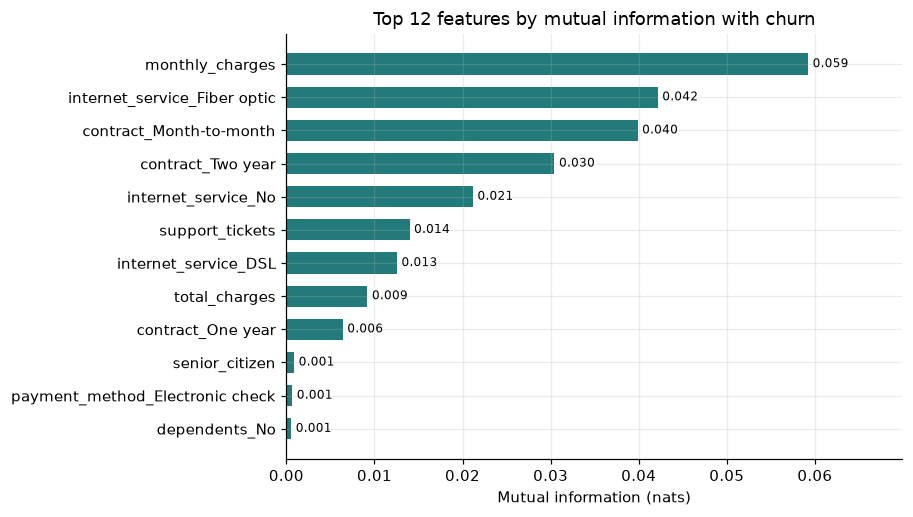

In [57]:
top = ranking.head(12).sort_values("mutual_information")
fig, ax = plt.subplots(figsize=(8.4, 4.8))
bars = ax.barh(top["feature"], top["mutual_information"], color="#237A7A", height=0.64)
ax.bar_label(bars, labels=[f"{v:.3f}" for v in top["mutual_information"]], padding=3, fontsize=8)
ax.set_title("Top 12 features by mutual information with churn")
ax.set_xlabel("Mutual information (nats)")
ax.set_xlim(0, top["mutual_information"].max() * 1.18)
plt.tight_layout(); plt.show()

In [58]:
# Any feature with a zero score carries no detectable information on its own.
zero_features = ranking.loc[ranking["mutual_information"] == 0, "feature"].tolist()
print(f"Features with zero mutual information: {len(zero_features)}")
print(zero_features)

print("\nCaveat: MI scores each feature on its own. Two features that are useless alone")
print("can still be valuable together (XOR is the classic example).")

Features with zero mutual information: 2
['tenure_months', 'payment_method_Mailed check']

Caveat: MI scores each feature on its own. Two features that are useless alone
can still be valuable together (XOR is the classic example).


### 9.4 Selecting the top-k features

Mutual information gives a ranking, not a cut-off. Two practical options:

* take the top `k` features (simple, arbitrary);
* take every feature above a threshold, or use `SelectKBest`.

Whatever you choose must be fitted on **training data only**. Ranking on the full dataset
and then training leaks target information; here the ranking is an explanatory artifact
for the report, and the modelling code re-fits selection within the training folds.

In [59]:
from sklearn.feature_selection import SelectKBest

selector = SelectKBest(mutual_info_classif, k=10)
X_selected = selector.fit_transform(feature_matrix, y)
chosen = [name for name, keep in zip(feature_names, selector.get_support()) if keep]

print(f"Selected {len(chosen)} of {len(feature_names)} encoded features:")
for name in chosen:
    print("  ", name)
print(f"\nShape before: {feature_matrix.shape}  ->  after: {X_selected.shape}")

Selected 10 of 21 encoded features:
   monthly_charges
   support_tickets
   contract_Month-to-month
   contract_One year
   contract_Two year
   internet_service_DSL
   internet_service_Fiber optic
   internet_service_No
   payment_method_Mailed check
   paperless_billing_Yes

Shape before: (1800, 21)  ->  after: (1800, 10)


---
## 10 · Putting it together: the model-ready dataset

The individual steps are now combined into a single `Pipeline`. A pipeline guarantees
that the **same transformations, with the same learned parameters**, are applied at
training time and at prediction time. This is the single most important
preprocessing discipline.

### 10.1 The complete pipeline

In [60]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score

full_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=2000, class_weight="balanced",
                                 random_state=RANDOM_STATE)),
])

full_pipeline.fit(X_train, y_train)

predictions = full_pipeline.predict(X_test)
probabilities = full_pipeline.predict_proba(X_test)[:, 1]

print(f"Held-out accuracy : {accuracy_score(y_test, predictions):.4f}")
print(f"Held-out ROC-AUC  : {roc_auc_score(y_test, probabilities):.4f}")
print("\nThis is a smoke test that the preprocessing is model-ready,")
print("not a tuned model and not a Week 1 deliverable.")

Held-out accuracy : 0.6806
Held-out ROC-AUC  : 0.7694

This is a smoke test that the preprocessing is model-ready,
not a tuned model and not a Week 1 deliverable.


### 10.2 Why the pipeline matters

The pipeline stores every learned parameter: medians, modes, category lists, means and
standard deviations. Serialising it means a future request can send **raw** fields and
receive a prediction, with no manual preprocessing and no risk of applying a different
scaling than the one used in training.

In [61]:
preprocessor_step = full_pipeline.named_steps["preprocessor"]
numeric_pipe = preprocessor_step.named_transformers_["numeric"]
categorical_pipe = preprocessor_step.named_transformers_["categorical"]

numeric_imputer = numeric_pipe.named_steps["imputer"]
numeric_scaler = numeric_pipe.named_steps["scaler"]
categorical_imputer = categorical_pipe.named_steps["imputer"]

learned = {
    "numeric_imputation_values": {
        name: round(float(value), 2)
        for name, value in zip(numeric_features, numeric_imputer.statistics_)
    },
    "numeric_missing_indicators": {
        name: str(feature)
        for name, feature in zip(
            numeric_features, numeric_imputer.indicator_.features_
        )
    }
    if numeric_imputer.indicator_ is not None
    else {},
    "standard_scaler_mean": {
        name: round(float(value), 3)
        for name, value in zip(numeric_features, numeric_scaler.mean_)
    },
    "standard_scaler_scale": {
        name: round(float(value), 3)
        for name, value in zip(numeric_features, numeric_scaler.scale_)
    },
    "categorical_modes": {
        name: value
        for name, value in zip(categorical_features, categorical_imputer.statistics_)
    },
}

import json

print(json.dumps(learned, indent=2))

{
  "numeric_imputation_values": {
    "tenure_months": 37.0,
    "monthly_charges": 64.34,
    "total_charges": 2020.29,
    "support_tickets": 1.0,
    "senior_citizen": 0.0
  },
  "numeric_missing_indicators": {},
  "standard_scaler_mean": {
    "tenure_months": 37.065,
    "monthly_charges": 61.219,
    "total_charges": 2224.839,
    "support_tickets": 1.008,
    "senior_citizen": 0.17
  },
  "standard_scaler_scale": {
    "tenure_months": 16.719,
    "monthly_charges": 21.123,
    "total_charges": 1332.557,
    "support_tickets": 1.038,
    "senior_citizen": 0.376
  },
  "categorical_modes": {
    "contract": "Month-to-month",
    "internet_service": "Fiber optic",
    "payment_method": "Bank transfer",
    "paperless_billing": "Yes",
    "partner": "Yes",
    "dependents": "No"
  }
}


### 10.3 Predict one raw record

This is the real test of a preprocessing design: can an untouched record go straight in?

In [62]:
new_customer = pd.DataFrame([{
    "tenure_months": 4,
    "monthly_charges": 105.0,
    "total_charges": 420.0,
    "support_tickets": 4,
    "senior_citizen": 0,
    "contract": "Month-to-month",
    "internet_service": "Fiber optic",
    "payment_method": "Electronic check",
    "paperless_billing": "Yes",
    "partner": "No",
    "dependents": "No",
}])

prediction = full_pipeline.predict(new_customer)[0]
probability = full_pipeline.predict_proba(new_customer)[0, 1]
print("Raw record accepted without manual preprocessing.")
print(f"Prediction : {'Yes (churn)' if prediction == 1 else 'No (retain)'}")
print(f"P(churn)   : {probability:.3f}")

Raw record accepted without manual preprocessing.
Prediction : Yes (churn)
P(churn)   : 0.986


In [63]:
# Missing fields and an unseen category are also tolerated.
incomplete_customer = pd.DataFrame([{
    "tenure_months": None,
    "monthly_charges": None,
    "total_charges": None,
    "support_tickets": None,
    "senior_citizen": None,
    "contract": "Lifetime deal",       # unseen at fit time
    "internet_service": None,
    "payment_method": None,
    "paperless_billing": None,
    "partner": None,
    "dependents": None,
}])

print("All-missing record with an unseen category:")
print(f"  prediction : {full_pipeline.predict(incomplete_customer)[0]}")
print(f"  P(churn)   : {full_pipeline.predict_proba(incomplete_customer)[0, 1]:.3f}")
print("\nThe pipeline imputes, ignores the unseen level, and still returns an answer.")

All-missing record with an unseen category:
  prediction : 0
  P(churn)   : 0.292

The pipeline imputes, ignores the unseen level, and still returns an answer.


### 10.4 The documented preprocessing record

Every decision is recorded in the JSON summary written by `src/preprocess.py`, so the
report and the code cannot drift apart. Below is the shape of that record.

In [64]:
import json

summary_path = OUTPUT_DIR / "preprocessing_summary.json"
if summary_path.exists():
    summary = json.loads(summary_path.read_text())
    print("Keys in preprocessing_summary.json:")
    for key in summary:
        print("  ", key)
    print("\nFinal dataset:")
    print(json.dumps(summary["final_dataset"], indent=2)[:700], "...")
else:
    print(f"{summary_path} not found - run `python src/preprocess.py` first.")

Keys in preprocessing_summary.json:
   project
   generated_at_utc
   dataset
   quality_audit
   cleaning
   missing_values
   outliers
   encoding
   scaling
   feature_selection
   final_dataset
   model_readiness_check
   artifacts

Final dataset:
{
  "rows": 1800,
  "model_features": 25,
  "remaining_missing_cells": 0,
  "target_encoding": "No = 0, Yes = 1",
  "features": [
    "tenure_months",
    "monthly_charges",
    "total_charges",
    "support_tickets",
    "senior_citizen",
    "missingindicator_tenure_months",
    "missingindicator_monthly_charges",
    "missingindicator_total_charges",
    "missingindicator_support_tickets",
    "contract_Month-to-month",
    "contract_One year",
    "contract_Two year",
    "internet_service_DSL",
    "internet_service_Fiber optic",
    "internet_service_No",
    "payment_method_Bank transfer",
    "payment_method_Credit card",
    "payment_method_Electronic check",
    "payment_method_Mai ...


---
## 11 · Summary and checkpoint

You have now exercised the complete Week 1 skill set on one dataset.

| Stage | Technique | Result on this data |
|---|---|---|
| Loading | `pd.read_csv` with `na_values` | 1,800 rows × 13 columns |
| Audit | dtypes, duplicates, invalid-value checks | 562 missing feature cells |
| Cleaning | trim, type repair, deduplication | 0 duplicates; no rows lost |
| Missing values | median + indicator, mode | 10 columns imputed, 0 cells left |
| EDA | histograms, group rates, correlation, IQR | 8 figures, patterns documented |
| Encoding | `OneHotEncoder(handle_unknown="ignore")` | 6 → 16 columns |
| Scaling | `StandardScaler` | mean 0, std 1 per feature |
| Selection | mutual information | ranking + top-10 export |
| Integration | `Pipeline` | raw record → prediction |

### Checklist before calling preprocessing finished

- [x] Target defined and validated; class balance measured.
- [x] Identifier excluded from model inputs.
- [x] Duplicates and impossible values handled explicitly.
- [x] Missingness counted, stated, and imputed with a named strategy.
- [x] Missing indicators retained where missingness could be informative.
- [x] Every transformation learned from training data only.
- [x] Unseen categories tolerated at prediction time.
- [x] Zero missing values in the final matrix, asserted and printed.
- [x] Every number in the report reproducible from a fixed seed.

### Where to go next

* **Week 2** trains and compares supervised models on this prepared data.
* **Week 3** adds clustering, PCA and cross-validated evaluation.
* **Week 4** serialises the whole pipeline behind a prediction API.

### Common mistakes this notebook guards against

1. **Imputing with the whole-dataset median** — leaks test information; fit on train.
2. **Scaling before splitting** — same problem.
3. **Dropping rows with any missing value** — loses a quarter of this dataset.
4. **`get_dummies` in a pipeline** — the category list is not stored, so a new level crashes prediction.
5. **Flagging binary columns as outliers** — every `1` looks anomalous to an IQR rule.
6. **Trusting accuracy on imbalanced data** — 73% accuracy here beats a constant "No" model by zero.
7. **Reading correlation as causation** — the plots describe this sample, nothing more.
8. **Leaving `customer_id` in the feature matrix** — a unique identifier has no generalisable predictive value and can memorise the training rows.

> The dataset is synthetic. Every number in this notebook demonstrates workflow
> mechanics; none of it is evidence about real customer behaviour.